In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

%matplotlib inline
sns.set_style("whitegrid")
plt.style.use("fivethirtyeight")

In [ ]:
data = pd.read_csv("heart.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# Exploring dataset
data.shape
data.info()
data.describe()
data.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


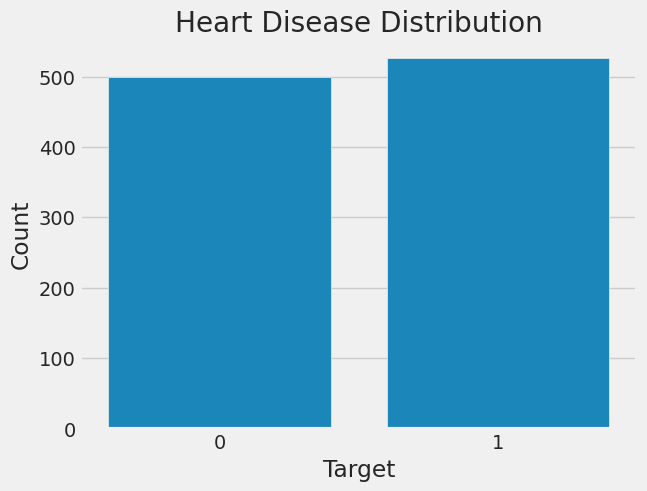

In [ ]:
# Understanding about target variable
data['target'].value_counts()

# Let's visualize
sns.countplot(x='target', data=data)
plt.title('Heart Disease Distribution')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

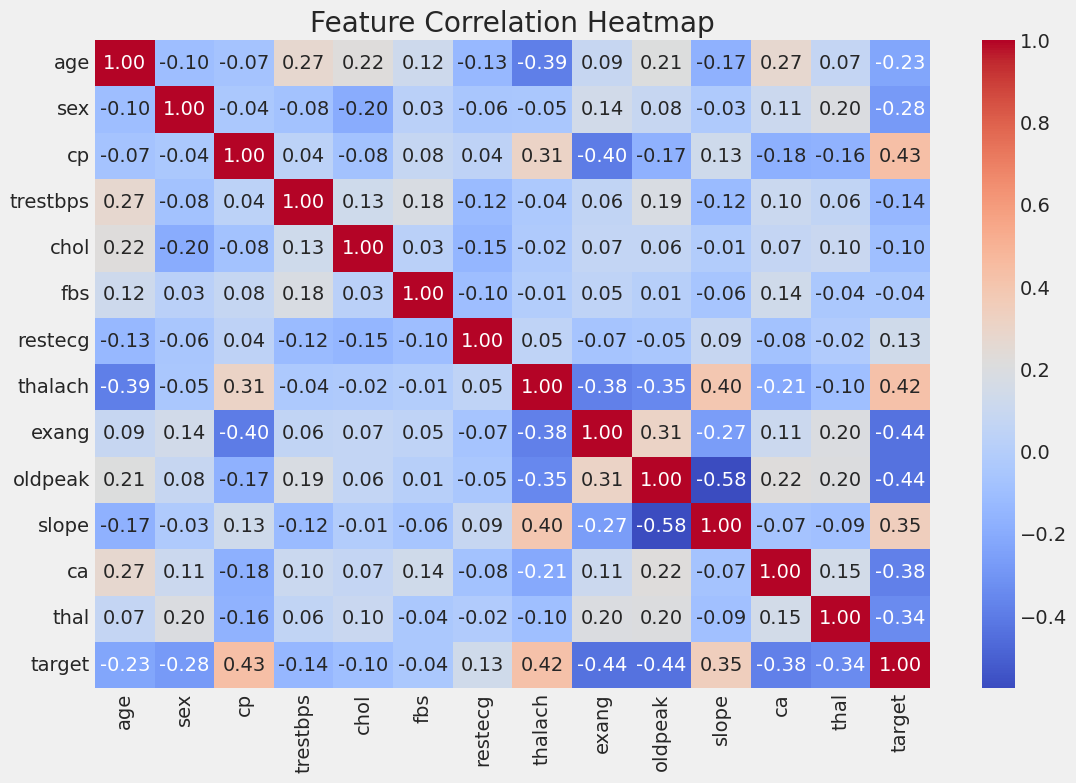

In [ ]:
# Exploratory Data Analysis

# A. Correlation Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Feature Correlation Heatmap')
plt.show()


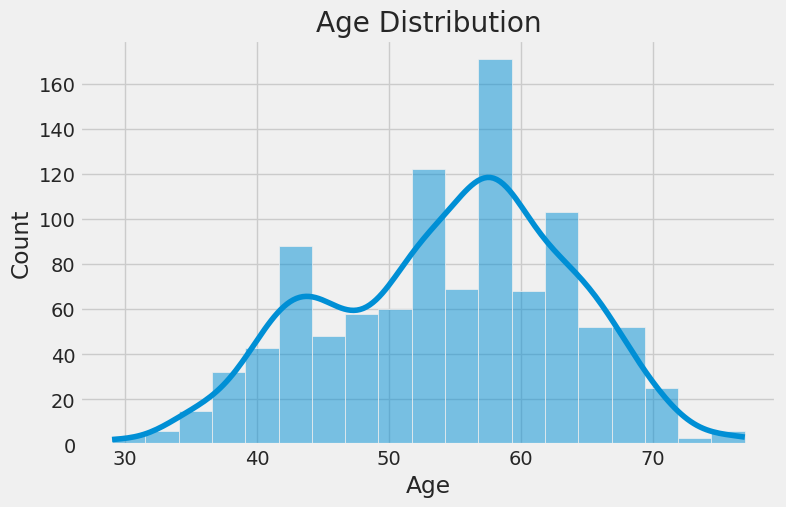

In [ ]:
# B. Age Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data['age'], kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()

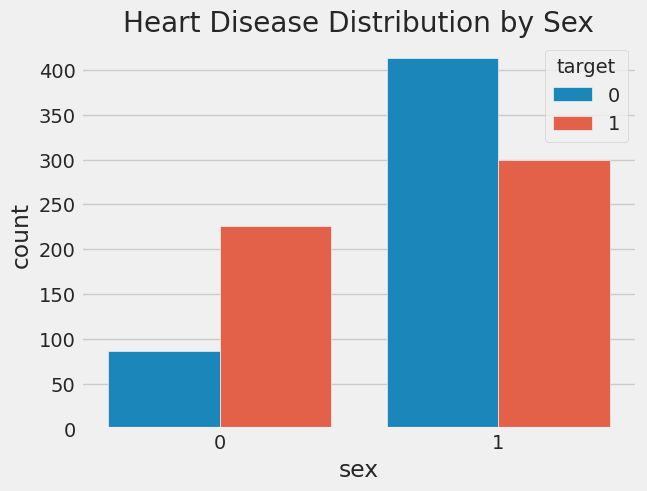

In [ ]:
# C. Gender Distribution

sns.countplot(x='sex', data=data, hue='target')

plt.title('Heart Disease Distribution by Sex')
plt.show()

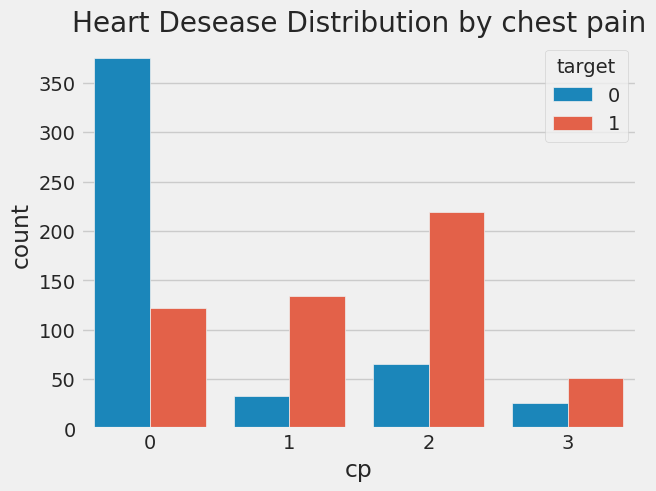

In [ ]:
# D. Chest Pain

sns.countplot(x='cp', data=data, hue='target')

plt.title('Heart Desease Distribution by chest pain')
plt.show()

In [ ]:
# Pheww!! Let's start Data Pre processing

# Separating Features and targets and splitting dataset into train-test (80-20)
X = data.drop("target", axis=1)
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [ ]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
# Training the model

model = DecisionTreeClassifier(max_depth=2)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=2)

[Text(0.5, 0.8333333333333334, 'x[2] <= -0.435\ngini = 0.499\nsamples = 820\nvalue = [397, 423]'),
 Text(0.25, 0.5, 'x[11] <= -0.243\ngini = 0.371\nsamples = 398\nvalue = [300, 98]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.5\nsamples = 177\nvalue = [87, 90]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.07\nsamples = 221\nvalue = [213, 8]'),
 Text(0.75, 0.5, 'x[12] <= 0.283\ngini = 0.354\nsamples = 422\nvalue = [97, 325]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.234\nsamples = 317\nvalue = [43, 274]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.5\nsamples = 105\nvalue = [54.0, 51.0]')]

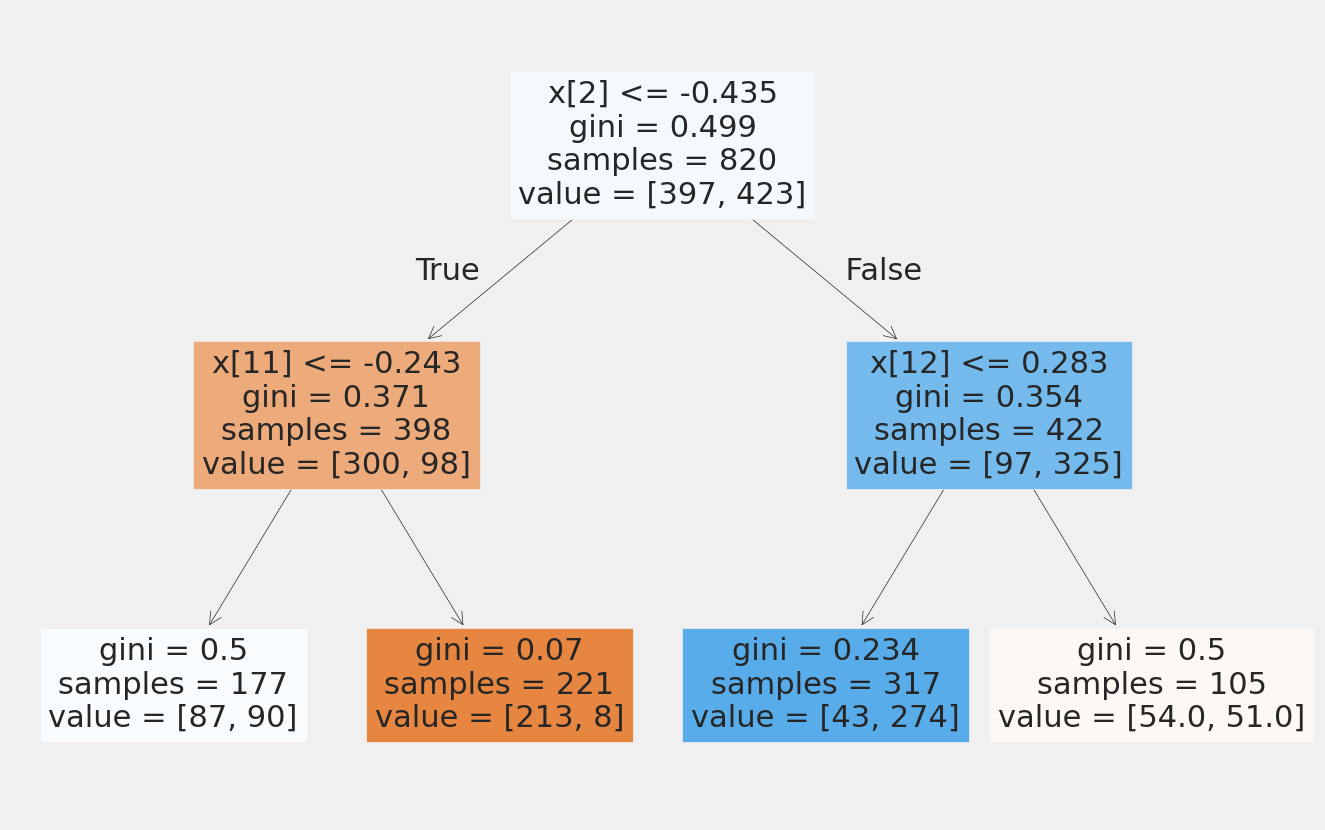

In [22]:
plt.figure(figsize=(15,10))
tree.plot_tree(model, filled=True)

In [23]:
# Making Predictions

y_pred = model.predict(X_test_scaled)

In [24]:
# Calculating Evaluation Metrics

from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.6780487804878049

Classification Report:

              precision    recall  f1-score   support

           0       0.71      0.60      0.65       102
           1       0.66      0.76      0.70       103

    accuracy                           0.68       205
   macro avg       0.68      0.68      0.68       205
weighted avg       0.68      0.68      0.68       205



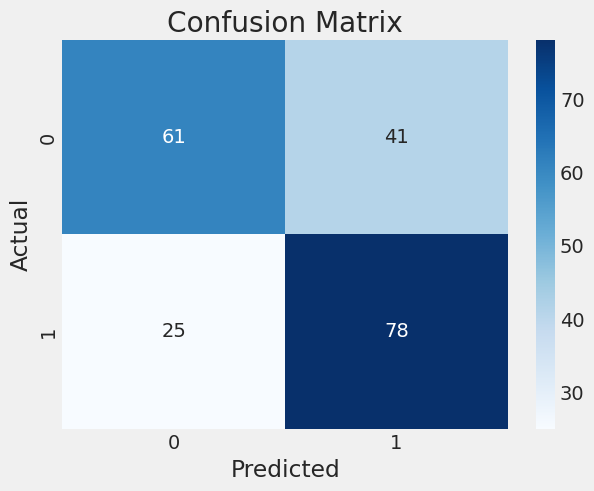

In [25]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()